#O que são metadados?

Importando bibliotecas

In [2]:
# Importando bibliotecas

import pandas as pd

Lendo o arquivo parquet

In [3]:
# Lendo o arquivo PARQUET

df = pd.read_parquet("./dados/results.parquet")

In [4]:
df.columns = ["", "", "", "", "", "", ""]

Mostrando o conjunto de dados sem metadados

In [5]:
# Removendo o índice das linhas do dataframe

df.head(15).style.hide(axis="index")

,,,,,,
2012,2012-03-10 05:00:00+00:00,Gamba Osaka,Vissel Kobe,2,3,A
2012,2012-03-10 05:00:00+00:00,Sanfrecce Hiroshima,Urawa Reds,1,0,H
2012,2012-03-10 05:00:00+00:00,Nagoya Grampus,Shimizu S-Pulse,1,0,H
2012,2012-03-10 05:00:00+00:00,Sagan Tosu,Cerezo Osaka,0,0,D
2012,2012-03-10 05:00:00+00:00,Hokkaido Consadole Sapporo,Iwata,0,0,D
2012,2012-03-10 05:00:00+00:00,Vegalta Sendai,Kashima Antlers,1,0,H
2012,2012-03-10 08:00:00+00:00,Kawasaki Frontale,Albirex Niigata,1,0,H
2012,2012-03-10 10:00:00+00:00,Omiya Ardija,FC Tokyo,0,1,A
2012,2012-03-11 05:00:00+00:00,Kashiwa Reysol,Yokohama F. Marinos,3,3,D
2012,2012-03-17 05:00:00+00:00,Albirex Niigata,Omiya Ardija,1,2,A



----


Criando um dicionário de dados

In [6]:
dados = pd.read_parquet("./dados/results.parquet")

Retomando os dados com os metadados

In [7]:
dados.head(5)

,Season,DateTime,Home,Away,HG,AG,Res
0,2012,2012-03-10 05:00:00+00:00,Gamba Osaka,Vissel Kobe,2,3,A
1,2012,2012-03-10 05:00:00+00:00,Sanfrecce Hiroshima,Urawa Reds,1,0,H
2,2012,2012-03-10 05:00:00+00:00,Nagoya Grampus,Shimizu S-Pulse,1,0,H
3,2012,2012-03-10 05:00:00+00:00,Sagan Tosu,Cerezo Osaka,0,0,D
4,2012,2012-03-10 05:00:00+00:00,Hokkaido Consadole Sapporo,Iwata,0,0,D


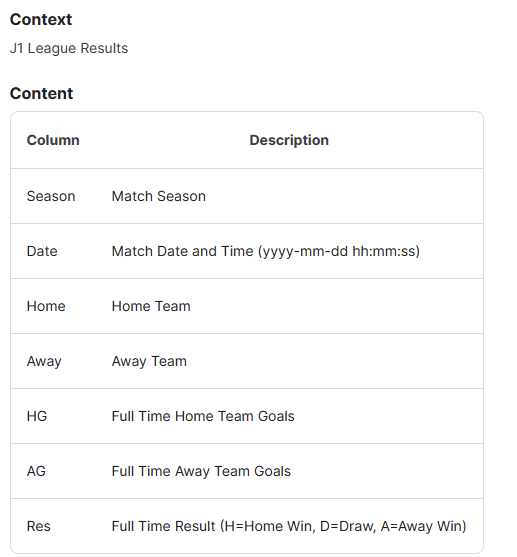

Criando um dicionário de dados

In [8]:
dicionario = pd.DataFrame()

Atribuindo o nome das colunas no dicionario de dados

In [9]:
dicionario["Coluna"] = dados.columns
dicionario

,Coluna
0,Season
1,DateTime
2,Home
3,Away
4,HG
5,AG
6,Res


Criando descrições para as colunas

In [10]:
descricoes = [
    "Temporada na qual a partida foi disputada",
    "Data e hora na qual a partida foi disputada",
    "Time da casa",
    "Time visitante",
    "Quantidade de gols marcados pelo time da casa em tempo regular",
    "Quantidade de gols marcados pelo time visitante em tempo regular",
    "Resultado da partida",
]
dicionario["Descricao"] = descricoes
dicionario

,Coluna,Descricao
0,Season,Temporada na qual a partida foi disputada
1,DateTime,Data e hora na qual a partida foi disputada
2,Home,Time da casa
3,Away,Time visitante
4,HG,Quantidade de gols marcados pelo time da casa ...
5,AG,Quantidade de gols marcados pelo time visitant...
6,Res,Resultado da partida


Entendendo valores possíveis para as colunas

In [11]:
# Quantidade de temporadas no dataset
dados.Season.value_counts()

Season
2021    380
2019    310
2015    309
2016    309
2018    309
2012    306
2013    306
2014    306
2017    306
2020    306
2022     66
Name: count, dtype: int64

In [12]:
# Quantidade de times que jogaram em casa
dados.Home.unique()

<ArrowStringArray>
[               'Gamba Osaka',        'Sanfrecce Hiroshima',
             'Nagoya Grampus',                 'Sagan Tosu',
 'Hokkaido Consadole Sapporo',             'Vegalta Sendai',
          'Kawasaki Frontale',               'Omiya Ardija',
             'Kashiwa Reysol',            'Albirex Niigata',
               'Cerezo Osaka',            'Kashima Antlers',
                 'Urawa Reds',        'Yokohama F. Marinos',
            'Shimizu S-Pulse',                      'Iwata',
                'Vissel Kobe',                   'FC Tokyo',
               'Oita Trinita',                       'Kofu',
            'Shonan Bellmare',                  'Tokushima',
                     'Yamaga',          'Montedio Yamagata',
             'Avispa Fukuoka',           'V-Varen Nagasaki',
                'Yokohama FC',                      'Kyoto']
Length: 28, dtype: str

In [13]:
# Quantidade de times que jogaram fora de casa
dados.Away.unique()

<ArrowStringArray>
[               'Vissel Kobe',                 'Urawa Reds',
            'Shimizu S-Pulse',               'Cerezo Osaka',
                      'Iwata',            'Kashima Antlers',
            'Albirex Niigata',                   'FC Tokyo',
        'Yokohama F. Marinos',               'Omiya Ardija',
                'Gamba Osaka',          'Kawasaki Frontale',
             'Kashiwa Reysol',             'Vegalta Sendai',
        'Sanfrecce Hiroshima',                 'Sagan Tosu',
 'Hokkaido Consadole Sapporo',             'Nagoya Grampus',
                       'Kofu',            'Shonan Bellmare',
               'Oita Trinita',                  'Tokushima',
                     'Yamaga',          'Montedio Yamagata',
             'Avispa Fukuoka',           'V-Varen Nagasaki',
                      'Verdy',                'Yokohama FC',
                      'Kyoto']
Length: 29, dtype: str

In [14]:
# Gols marcados pelo time da casa
dados.HG.max()

np.int32(8)

In [15]:
# Quantidade de gols marcados pelo time visitante
dados.AG.max()

np.int32(8)

In [16]:
# Quantidade de resultados possíveis
dados.Res.unique()

<ArrowStringArray>
['A', 'H', 'D']
Length: 3, dtype: str

Criando metadados de valores possíveis

In [17]:
dicionario["valores_possiveis"] = [
    "2012-2022",
    "2012-2022",
    """'Gamba Osaka', 'Sanfrecce Hiroshima', 'Nagoya Grampus', 'Sagan Tosu', 'Hokkaido Consadole Sapporo', 'Vegalta Sendai', 'Kawasaki Frontale', 'Omiya Ardija', 'Kashiwa Reysol', 'Albirex Niigata', 'Cerezo Osaka', 'Kashima Antlers', 'Urawa Reds', 'Yokohama F. Marinos', 'Shimizu S-Pulse', 'Iwata', 'Vissel Kobe', 'FC Tokyo', 'Oita Trinita', 'Kofu', 'Shonan Bellmare', 'Tokushima', Yamaga', 'Montedio Yamagata', 'Avispa Fukuoka', 'V-Varen Nagasaki', 'Yokohama FC', 'Kyoto'""",
    """'Vissel Kobe', 'Urawa Reds', 'Shimizu S-Pulse', 'Cerezo Osaka', 'Iwata', 'Kashima Antlers', 'Albirex Niigata', 'FC Tokyo', 'Yokohama F. Marinos', 'Omiya Ardija', 'Gamba Osaka', 'Kawasaki Frontale', 'Kashiwa Reysol', 'Vegalta Sendai', 'Sanfrecce Hiroshima', 'Sagan Tosu', 'Hokkaido Consadole Sapporo', 'Nagoya Grampus', 'Kofu', 'Shonan Bellmare', 'Oita Trinita', 'Tokushima', 'Yamaga', 'Montedio Yamagata', 'Avispa Fukuoka', 'V-Varen Nagasaki', 'Verdy', 'Yokohama FC', 'Kyoto'""",
    "0-8",
    "0-8",
    "A: time visitante ganha, H: time da casa ganha, D: empate",
]

Analisando o dicionário de dados

In [18]:
dicionario

,Coluna,Descricao,valores_possiveis
0,Season,Temporada na qual a partida foi disputada,2012-2022
1,DateTime,Data e hora na qual a partida foi disputada,2012-2022
2,Home,Time da casa,"'Gamba Osaka', 'Sanfrecce Hiroshima', 'Nagoya ..."
3,Away,Time visitante,"'Vissel Kobe', 'Urawa Reds', 'Shimizu S-Pulse'..."
4,HG,Quantidade de gols marcados pelo time da casa ...,0-8
5,AG,Quantidade de gols marcados pelo time visitant...,0-8
6,Res,Resultado da partida,"A: time visitante ganha, H: time da casa ganha..."


# Extraindo metadados de dados não estruturados

## 2.3 Extraindo metadados de uma imagem

Instalando a biblioteca que vamos usar

In [20]:
%pip install Pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 18.2 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


Importando funções importantes

In [21]:
from PIL import Image
from PIL.ExifTags import TAGS

Criando o objeto imagem

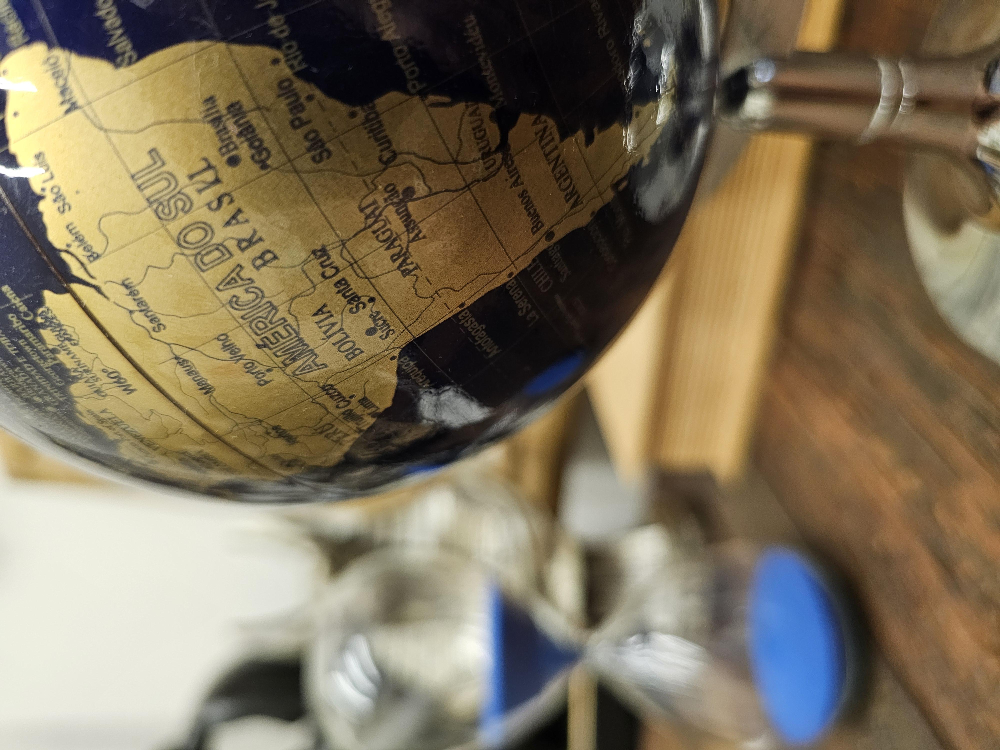

In [24]:
foto = Image.open("./dados/20240314_225158.jpg")
foto

In [25]:
foto.filename

'./dados/20240314_225158.jpg'

In [26]:
foto.size

(4000, 3000)

In [27]:
foto.height

3000

In [28]:
foto.width

4000

In [29]:
foto.format

'JPEG'

In [30]:
foto.mode

'RGB'

## 2.4 Aprofundando a extração de metadados

Acessando os metdados

In [ ]:
metadados = foto.getexif()

In [ ]:
# Exibindo os metadados da imagem
for tag_id, tag_name in TAGS.items():
    if tag_id in metadados:
        print(tag_name, ":", metadados[tag_id])

ImageWidth : 4000
ImageLength : 3000
Make : samsung
Model : Galaxy S23 Ultra
Orientation : 6
XResolution : 72.0
YResolution : 72.0
ResolutionUnit : 2
Software : S918BXXS3BXB2
DateTime : 2024:03:14 22:51:57
YCbCrPositioning : 1
ExifOffset : 234


## 2.5 Extraindo metadaos de um vídeo no Youtube

https://mattw.io/youtube-metadata/

https://www.youtube.com/watch?v=-CbFz9cvWhE

Trazendo os metadados para o Colab

In [ ]:
{
    "publishedAt": "2023-11-21T18:36:31Z",
    "channelId": "UCo7EHzKF2zDFWszw7Dg4mPw",
    "title": "Guia de Carreira: Engenharia de Dados",
    "description": '📊💻 Explore o melhor da Engenharia de Dados para impulsionar sua carreira com nossas trilhas com cursos especializados do Tech Guide.\n_____________________________\nNo Tech Guide, mergulhe na essência da Engenharia de Dados, explorando desde fundamentos até conceitos avançados. Descubra capítulos detalhados sobre Linguagem Python para manipulação de dados, sistemas operacionais Linux e sua integração com pipelines, Data Lake e ETL. Explore Apache Spark para lidar com Big Data, contêineres e ambientes de Cloud. Aprofunde-se em bancos de dados relacionais e não-relacionais, descubra Data Mesh e diferentes tipos de Engenharia de Dados. Desvende a interseção entre Arquitetura de Software, Dados e Machine Learning para impulsionar sua carreira \n\n👥 Conheça quem será o Host desta temporada e as pessoas convidadas para o papo, que guiarão você durante os estudos:\n\n✅ Fabricio Carraro, Product Manager na Alura, Engenheiro da Computação (@tvunicamp) e Pós Tech em Data Analytics e Machine Learning (@FiapBrasil) | https://www.linkedin.com/in/fabriciocarraro/\n✅ Anselmo Borges, Especialista em Eng. de Dados na @portoseguro| https://www.linkedin.com/in/anselmoborges/?locale=pt_BR\n✅ Thiago Silva, Eng. de Dados Senior no @Itau | https://www.linkedin.com/in/thiago-cns/?originalSubdomain=br\n✅ Paola Brito, Eng. de Machine Learning no @Nubank | https://www.linkedin.com/in/paolabrito/\n\n💡 Confira também\n🧑‍🔧Carreira em Engenharia de dados da Alura: https://alura.tv/4nt5P8G\n\n🔗 Links mencionados\n\n📊 TechGuide de Engenharia de Dados: https://techguide.sh/pt-BR/path/data-engineering/\n📄 Paper do Google mencionado pelo Thiago: https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning?hl=pt-br\n\n🔎 Confira também...\n\n📑 Artigo "Engenharia de Dados" https://www.alura.com.br/artigos/engenharia-dados \n📑 Artigo "Big Data" https://www.alura.com.br/artigos/big-data \n📑 Artigo "Data Lake vs Data Warehouse" https://www.alura.com.br/artigos/data-lake-vs-data-warehouse \n📑 Artigo "O que faz uma pessoa engenheira de dados" https://www.alura.com.br/artigos/o-que-pessoa-engenheira-dados \n\n📂 Capítulos:\n\n▶ 00:00:00 - 00:01:05 - Tech Guide: Engenharia de Dados\n\n▶ 00:01:06 - 00:01:48 - Apresentação das pessoas convidadas\n\n▶ 00:01:49 - 00:02:06 - NÍVEL 01: Python, Linux, Pipeline, Big Data e mais\n\n▶ 00:02:07 - 00:03:17 - 1.1) O que é Engenharia de Dados?\n\n00:03:18 - 00:04:43 - 1.2) O que faz uma pessoa Engenheira de Dados?\n00:04:44 - 00:08:10 - 1.3) Linguagem Python e Sistema Operacional Linux\n00:08:11 - 00:11:52 - 1.4) Pipelines, Data Lake e ETL\n00:11:53 - 00:13:38 - 1.5) Data Lake vs Data Mesh\n00:13:39 - 00:17:31 - 1.6) Por onde começar em Eng. Dados?\n00:17:32 - 00:21:43 - 1.7) Big Data: Apache Spark\n\n▶ 00:21:44 - 00:22:11 - NÍVEL 02: Contêineres, Clouds, Banco de Dados e mais\n\n00:22:12 - 00:28:11 - 2.1) Contêineres e Clouds\n00:28:12 - 00:31:28 - 2.2) Data Warehouses, Big Query e mais\n00:31:29 - 00:35:23 - 2.3) Bancos de Dados relacionais e não-relacionais\n00:35:24 - 00:38:52 - 2.4) O que são Redes de Computadores e para que servem?\n\n▶ 00:38:53 - 00:39:19 - NÍVEL 03: Streaming, IaC, Deploy, CI/CD e mais\n\n00:39:20 - 00:41:43 - 3.1) Data Mesh e tipos de Eng. de Dados\n00:41:44 - 00:43:44 - 3.2) 3 Vs da Eng. Dados: Volume, Velocidade e Variedade\n00:43:45 - 00:47:24 - 3.3) Streaming: processamento e transmissão contínua de dados\n00:47:25 - 00:49:28 - 3.4) Infraestrutura como código (IaC)\n00:49:29 - 00:52:48 - 3.5) Deploy e Entrega e Integração contínuas (CI/CD)\n\n▶ 00:52:49 - 00:53:36 - T: Arquitetura de Software, Dados e Machine Learning\n\n00:53:37 - 00:56:37 - T.1) APIs e Analytics by Design\n00:56:38 - 01:03:48 - T.2) Estatística, Machine Learning, BI e MLOps\n\n▶ 01:03:49 - 01:04:50 - Acesse o Tech Guide Eng. Dados e comenta a sua opinião aqui\n\n📄 Inscreva-se na Newsletter com conteúdos de Imersão, aprendizagem e Tecnologia da Alura, com emails do nosso CEO: https://www.alura.com.br/imersao \n\n📲 Siga a Alura nas Redes Sociais\n\n➡ Instagram: https://www.instagram.com/aluraonline\n➡ Twitter: https://twitter.com/AluraOnline\n➡ Linkedin: https://www.linkedin.com/school/aluracursos\n➡ Facebook: https://www.facebook.com/AluraCursosOnline\n\n#engenhariadedados #roadmap #dados',
    "thumbnails": {
        "default": {
            "url": "https://i.ytimg.com/vi/-CbFz9cvWhE/default.jpg",
            "width": 120,
            "height": 90,
        },
        "medium": {
            "url": "https://i.ytimg.com/vi/-CbFz9cvWhE/mqdefault.jpg",
            "width": 320,
            "height": 180,
        },
        "high": {
            "url": "https://i.ytimg.com/vi/-CbFz9cvWhE/hqdefault.jpg",
            "width": 480,
            "height": 360,
        },
        "standard": {
            "url": "https://i.ytimg.com/vi/-CbFz9cvWhE/sddefault.jpg",
            "width": 640,
            "height": 480,
        },
        "maxres": {
            "url": "https://i.ytimg.com/vi/-CbFz9cvWhE/maxresdefault.jpg",
            "width": 1280,
            "height": 720,
        },
    },
    "channelTitle": "Alura",
    "tags": [
        "HipstersPontoTube",
        "Alura",
        "Tecnologia",
        "Dev",
        "Programação",
        "Carreira",
        "Tech guide",
        "Roadmap",
        "Engenharia de dados",
        "Data science",
        "Ciência de dados",
        "Análise de dados",
        "Analista de dados",
        "Engenheiro de dados",
        "Engenharia de dados ou ciência de dados",
        "Carreira engenharia de dados",
        "Python",
        "Java",
        "Linux",
        "Data lake",
        "Data mesh",
        "Big data",
        "Pipelines",
        "ETL",
        "Banco de dados",
        "Engenharia de dados na prática",
        "Engenharia de dados o que faz",
        "Cloud",
        "Engenheiro de dados jr",
        "Engenheiro de dados júnior",
        "Machine learning",
    ],
    "categoryId": "28",
    "liveBroadcastContent": "none",
    "defaultLanguage": "pt-PT",
    "localized": {
        "title": "Guia de Carreira: Engenharia de Dados",
        "description": '📊💻 Explore o melhor da Engenharia de Dados para impulsionar sua carreira com nossas trilhas com cursos especializados do Tech Guide.\n_____________________________\nNo Tech Guide, mergulhe na essência da Engenharia de Dados, explorando desde fundamentos até conceitos avançados. Descubra capítulos detalhados sobre Linguagem Python para manipulação de dados, sistemas operacionais Linux e sua integração com pipelines, Data Lake e ETL. Explore Apache Spark para lidar com Big Data, contêineres e ambientes de Cloud. Aprofunde-se em bancos de dados relacionais e não-relacionais, descubra Data Mesh e diferentes tipos de Engenharia de Dados. Desvende a interseção entre Arquitetura de Software, Dados e Machine Learning para impulsionar sua carreira \n\n👥 Conheça quem será o Host desta temporada e as pessoas convidadas para o papo, que guiarão você durante os estudos:\n\n✅ Fabricio Carraro, Product Manager na Alura, Engenheiro da Computação (@tvunicamp) e Pós Tech em Data Analytics e Machine Learning (@FiapBrasil) | https://www.linkedin.com/in/fabriciocarraro/\n✅ Anselmo Borges, Especialista em Eng. de Dados na @portoseguro| https://www.linkedin.com/in/anselmoborges/?locale=pt_BR\n✅ Thiago Silva, Eng. de Dados Senior no @Itau | https://www.linkedin.com/in/thiago-cns/?originalSubdomain=br\n✅ Paola Brito, Eng. de Machine Learning no @Nubank | https://www.linkedin.com/in/paolabrito/\n\n💡 Confira também\n🧑‍🔧Carreira em Engenharia de dados da Alura: https://alura.tv/4nt5P8G\n\n🔗 Links mencionados\n\n📊 TechGuide de Engenharia de Dados: https://techguide.sh/pt-BR/path/data-engineering/\n📄 Paper do Google mencionado pelo Thiago: https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning?hl=pt-br\n\n🔎 Confira também...\n\n📑 Artigo "Engenharia de Dados" https://www.alura.com.br/artigos/engenharia-dados \n📑 Artigo "Big Data" https://www.alura.com.br/artigos/big-data \n📑 Artigo "Data Lake vs Data Warehouse" https://www.alura.com.br/artigos/data-lake-vs-data-warehouse \n📑 Artigo "O que faz uma pessoa engenheira de dados" https://www.alura.com.br/artigos/o-que-pessoa-engenheira-dados \n\n📂 Capítulos:\n\n▶ 00:00:00 - 00:01:05 - Tech Guide: Engenharia de Dados\n\n▶ 00:01:06 - 00:01:48 - Apresentação das pessoas convidadas\n\n▶ 00:01:49 - 00:02:06 - NÍVEL 01: Python, Linux, Pipeline, Big Data e mais\n\n▶ 00:02:07 - 00:03:17 - 1.1) O que é Engenharia de Dados?\n\n00:03:18 - 00:04:43 - 1.2) O que faz uma pessoa Engenheira de Dados?\n00:04:44 - 00:08:10 - 1.3) Linguagem Python e Sistema Operacional Linux\n00:08:11 - 00:11:52 - 1.4) Pipelines, Data Lake e ETL\n00:11:53 - 00:13:38 - 1.5) Data Lake vs Data Mesh\n00:13:39 - 00:17:31 - 1.6) Por onde começar em Eng. Dados?\n00:17:32 - 00:21:43 - 1.7) Big Data: Apache Spark\n\n▶ 00:21:44 - 00:22:11 - NÍVEL 02: Contêineres, Clouds, Banco de Dados e mais\n\n00:22:12 - 00:28:11 - 2.1) Contêineres e Clouds\n00:28:12 - 00:31:28 - 2.2) Data Warehouses, Big Query e mais\n00:31:29 - 00:35:23 - 2.3) Bancos de Dados relacionais e não-relacionais\n00:35:24 - 00:38:52 - 2.4) O que são Redes de Computadores e para que servem?\n\n▶ 00:38:53 - 00:39:19 - NÍVEL 03: Streaming, IaC, Deploy, CI/CD e mais\n\n00:39:20 - 00:41:43 - 3.1) Data Mesh e tipos de Eng. de Dados\n00:41:44 - 00:43:44 - 3.2) 3 Vs da Eng. Dados: Volume, Velocidade e Variedade\n00:43:45 - 00:47:24 - 3.3) Streaming: processamento e transmissão contínua de dados\n00:47:25 - 00:49:28 - 3.4) Infraestrutura como código (IaC)\n00:49:29 - 00:52:48 - 3.5) Deploy e Entrega e Integração contínuas (CI/CD)\n\n▶ 00:52:49 - 00:53:36 - T: Arquitetura de Software, Dados e Machine Learning\n\n00:53:37 - 00:56:37 - T.1) APIs e Analytics by Design\n00:56:38 - 01:03:48 - T.2) Estatística, Machine Learning, BI e MLOps\n\n▶ 01:03:49 - 01:04:50 - Acesse o Tech Guide Eng. Dados e comenta a sua opinião aqui\n\n📄 Inscreva-se na Newsletter com conteúdos de Imersão, aprendizagem e Tecnologia da Alura, com emails do nosso CEO: https://www.alura.com.br/imersao \n\n📲 Siga a Alura nas Redes Sociais\n\n➡ Instagram: https://www.instagram.com/aluraonline\n➡ Twitter: https://twitter.com/AluraOnline\n➡ Linkedin: https://www.linkedin.com/school/aluracursos\n➡ Facebook: https://www.facebook.com/AluraCursosOnline\n\n#engenhariadedados #roadmap #dados',
    },
    "defaultAudioLanguage": "pt",
}


# 3. Trabalhando com os metadados de um arquivo parquet

## 3.1 Acessando o schema do dataset

Importando a biblioteca Pyarrow

Lendo os dados

Acessando o schema

Acessando os metadados do schema

### 3.2 Alterando metadados de um arquivo parquet

### 3.4 escrevendo os novos metadados no dataset

Criando novos metadados

Substituindo os metadados pelos que criamos

Verificando as alterações nos dados

#4 Gerindo metadados

# 4.1 Trabalhando com uma nova base de dados

Criando um dataset com os dados da ONU

Criando um repositório central de metadados

Adicionando o nome da tabela

Adicionando nome físico das colunas

Adicionando nome lógico das colunas

Adicionando o tamanho em caracteres das colunas

Adicionando o tipo de dado

## 4.2 Criando metdados de negócio